In [ ]:
# Reference: https://www.youtube.com/watch?v=tHL5STNJKag
%pip install torch torchvision timm roboflow matplotlib pandas numpy tqdm Pillow ipywidgets
from gettext import install
import glob
import sys
import os
import pip
import roboflow
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
import timm
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from tqdm.notebook import tqdm
from PIL import Image

# Print versions for verification
print('System Version:', sys.version)
print('PyTorch version:', torch.__version__)
print('Torchvision version:', torchvision.__version__)
print('Numpy version:', np.__version__)
print('Pandas version:', pd.__version__)

Note: you may need to restart the kernel to use updated packages.
System Version: 3.10.15 | packaged by conda-forge | (main, Oct 16 2024, 01:15:49) [MSC v.1941 64 bit (AMD64)]
PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.2+cpu
Numpy version: 2.2.6
Pandas version: 2.3.3


In [ ]:
# Import configuration settings
try:
    from apiconfig import ROBOFLOW_API_KEY, WORKSPACE_NAME, PROJECT_NAME
except ImportError:
    raise ImportError(
        "Could not import from 'apiconfig.py'. "
        "Ensure 'apiconfig.py' exists in your workspace directory."
    )

# Validate API key and configuration
if not ROBOFLOW_API_KEY or ROBOFLOW_API_KEY == "None" or ROBOFLOW_API_KEY == "your_roboflow_api_key_here":
    raise ValueError(
        "Invalid ROBOFLOW_API_KEY detected! "
        "Please open 'apiconfig.py' and set ROBOFLOW_API_KEY to your actual string key "
        "(e.g., ROBOFLOW_API_KEY = 'xyz123...'), not None or 'None'."
    )

from roboflow import Roboflow

print(f"Connecting to Roboflow workspace '{WORKSPACE_NAME}', project '{PROJECT_NAME}'...")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)
project = rf.workspace(WORKSPACE_NAME).project(PROJECT_NAME)

# Dataset 3 from the MMA3001 brief uses version 4.
dataset_location = os.path.join(
    os.getcwd(),
    "Pork-Rasher-Error(Packaging)-4",
)
dataset_is_downloaded = (
    os.path.isfile(os.path.join(dataset_location, "data.yaml"))
    and os.path.isdir(os.path.join(dataset_location, "train", "images"))
    and os.path.isdir(os.path.join(dataset_location, "valid", "images"))
)
if dataset_is_downloaded:
    print("Using existing dataset at:", dataset_location)
else:
    dataset = project.version(4).download("yolov7", location=dataset_location)
    dataset_location = dataset.location
    print("Dataset downloaded successfully to:", dataset_location)


Connecting to Roboflow workspace 'hello-2aqe0', project 'pork-rasher-error-packaging'...
loading Roboflow workspace...
loading Roboflow project...
Using existing dataset at: c:\Users\blake\Downloads\Code-20261030T130158Z-1-001\Code\Pork-Rasher-Error(Packaging)-4


In [ ]:
"""
This dataset reads image files from a directory and pairs each image with its
corresponding annotation file. Each label file contains bounding-box entries
in YOLO format, which are transformed into a tensor suitable for model training.
"""

class PorkRasherPackagingDataset(Dataset):
    def __init__(self, images_dir, labels_dir, transform=None):
        """Initialize the dataset.

        Args:
            images_dir (str): Directory containing image files.
            labels_dir (str): Directory containing matching label files.
            transform (callable, optional): Optional image preprocessing pipeline.
                Defaults to None.
        """
        self.images_dir = images_dir
        self.labels_dir = labels_dir
        self.transform = transform
        self.image_paths = []
        for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.PNG'):
            self.image_paths.extend(glob.glob(os.path.join(self.images_dir, ext)))
        self.image_paths.sort()
    
    def __len__(self):
        """Return the total number of samples in the dataset.

        Returns:
            int: Number of image files found in `images_dir`.
        """
        return len(self.image_paths)
    
    def __getitem__(self, idx):
        """Return one image-label pair from the dataset.

        Args:
            idx (int): Index of the image to load.

        Returns:
            tuple: A tuple containing:
                - image (torch.Tensor): Image tensor after optional transforms.
                - label (torch.Tensor): YOLO-style labels reshaped to shape
                (num_boxes, 5), where each row is `[class_id, x_center, y_center,
                width, height]`.
        """
        image_path = self.image_paths[idx]
        image = Image.open(image_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        label_path = os.path.join(
            self.labels_dir,
            os.path.splitext(os.path.basename(image_path))[0] + ".txt",
        )
        with open(label_path, "r", encoding="utf-8") as label_file:
            label_rows = [
                [float(value) for value in line.split()]
                for line in label_file
                if line.strip()
            ]
        label = torch.tensor(label_rows, dtype=torch.float32).reshape(-1, 5)
        return image, label

#images already resized to 320x320 in the dataset so i can test at a reasonable time
transform = transforms.Compose([ transforms.Resize((320, 320)), transforms.ToTensor(), ])

trainingdataset = PorkRasherPackagingDataset(
    images_dir=os.path.join(dataset_location, "train", "images"),
    labels_dir=os.path.join(dataset_location, "train", "labels"),
    transform=transform
) 


print((trainingdataset.__getitem__(4)))



(tensor([[[0.1176, 0.1216, 0.1294,  ..., 0.1569, 0.1490, 0.1569],
         [0.0706, 0.0627, 0.0706,  ..., 0.1961, 0.1804, 0.1686],
         [0.0627, 0.0353, 0.0275,  ..., 0.2039, 0.1922, 0.2078],
         ...,
         [0.1020, 0.0902, 0.0667,  ..., 0.9882, 1.0000, 1.0000],
         [0.1020, 0.0784, 0.0510,  ..., 1.0000, 1.0000, 0.9922],
         [0.0980, 0.0745, 0.0353,  ..., 1.0000, 0.9961, 0.9569]],

        [[0.1451, 0.1412, 0.1373,  ..., 0.1725, 0.1922, 0.2157],
         [0.0902, 0.0745, 0.0745,  ..., 0.2039, 0.2157, 0.2157],
         [0.0745, 0.0431, 0.0235,  ..., 0.2078, 0.2078, 0.2275],
         ...,
         [0.1294, 0.1098, 0.0745,  ..., 0.9333, 0.9490, 0.9098],
         [0.1216, 0.0902, 0.0549,  ..., 0.9255, 0.9373, 0.8784],
         [0.1137, 0.0784, 0.0353,  ..., 0.9137, 0.9059, 0.8039]],

        [[0.2078, 0.2000, 0.1922,  ..., 0.1451, 0.1765, 0.2157],
         [0.1373, 0.1216, 0.1137,  ..., 0.1882, 0.2157, 0.2235],
         [0.0980, 0.0667, 0.0471,  ..., 0.2157, 0.2314, 0

In [ ]:
def collate_fn(batch):
    """
    Custom collate function to handle batches of images and labels.

    """
    images, labels = zip(*batch)
    return torch.stack(images), list(labels)


In [ ]:
"""Dataset and dataloader setup for the PorkRasher packaging model.

This cell prepares the training and validation datasets, wraps them in PyTorch
DataLoaders, and validates the batch shape before the training loop begins.
"""

# Training dataset
"""Load the training split for packaging detection.

Args:
    images_dir (str): Path to the directory containing training images.
    labels_dir (str): Path to the directory containing matching training labels.
    transform (callable, optional): Optional preprocessing pipeline applied to
        each image before it is returned by the dataset.

Returns:
    PorkRasherPackagingDataset: A dataset that yields image-label pairs for
    training examples.
"""
trainingdataset = PorkRasherPackagingDataset(
    images_dir=os.path.join(dataset_location, "train", "images"),
    labels_dir=os.path.join(dataset_location, "train", "labels"),
    transform=transform
)

# Validation dataset
"""Load the validation split for model evaluation.

Args:
    images_dir (str): Path to the directory containing validation images.
    labels_dir (str): Path to the directory containing matching validation labels.
    transform (callable, optional): Optional preprocessing pipeline applied to
        each image before it is returned by the dataset.

Returns:
    PorkRasherPackagingDataset: A dataset that yields image-label pairs for
    validation examples.
"""
validationdataset = PorkRasherPackagingDataset(
    images_dir=os.path.join(dataset_location, "valid", "images"),
    labels_dir=os.path.join(dataset_location, "valid", "labels"),
    transform=transform
)

# Training dataloader
"""Create a batched training iterator for model optimization.

This loader shuffles and groups training samples into mini-batches, making them
ready for the training loop. The `collate_fn` handles label formatting and batch
assembly for heterogeneous sample outputs.
"""
trainingdataloader = DataLoader(
    trainingdataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

# Validation dataloader
"""Create a batched validation iterator for evaluation.

This loader yields validation samples in fixed-size batches without shuffling,
allowing consistent metric reporting during model assessment.
"""
validationdataloader = DataLoader(
    validationdataset,
    batch_size=32,
    shuffle=False,
    collate_fn=collate_fn,
    num_workers=0
)

# Batch inspection
"""Inspect the first training batch to verify tensor shapes and label structure.

This sanity check ensures the dataset output matches the expected format before
the actual training loop runs.
"""
images, labels = next(iter(trainingdataloader))
print(f"First batch contains {len(labels)} label tensors:")
print(images.shape, labels[0].shape)  # Print the shape of the first label tensor
print(f"First label tensor:\n{labels[0]}")  # Print the first label tensor

First batch contains 32 label tensors:
torch.Size([32, 3, 320, 320]) torch.Size([1, 5])
First label tensor:
tensor([[1.0000, 0.8827, 0.7624, 0.0586, 0.0926]])


In [ ]:

# Use a reserved ID for images with no defects; YOLO class IDs are nonnegative.
NO_DEFECT_CLASS = -1

class_ids = set()
for label_path in glob.glob(os.path.join(trainingdataset.labels_dir, "*.txt")):
    with open(label_path, "r", encoding="utf-8") as label_file:
        for line in label_file:
            if line.strip():
                class_ids.add(int(float(line.split()[0])))

if not class_ids:
    raise ValueError("No defect class IDs found in the training labels.")

class_ids = sorted(class_ids)
class_to_index = {class_id: index for index, class_id in enumerate(class_ids)}
class_to_index[NO_DEFECT_CLASS] = len(class_to_index)
num_classes = len(class_to_index)

print("Class mapping (including no defects):", class_to_index)

print("Class IDs:", class_ids, "| Model outputs:", num_classes)


class PorkRasherClassifer(nn.Module):
    def __init__(self, num_classes):
        """
        Args:
        num_classes (int): Total number of output classes, including the
            reserved no-defect class.
        """
        super().__init__()
        self.base_model = timm.create_model("efficientnet_b0", pretrained=True)
        self.features = nn.Sequential(*list(self.base_model.children())[:-1])
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1280, num_classes),
        )
    
    def forward(self, x):
        """Forward pass through the model.
        
            Args:
                x (torch.Tensor): Input batch of images with shape
                    (batch_size, channels, height, width).
        
            Returns:
                torch.Tensor: Logits for each class for the current batch.
        """
        return self.classifier(self.features(x))


model = PorkRasherClassifer(num_classes=num_classes)

Class mapping (including no defects): {0: 0, 1: 1, 2: 2, 3: 3, 4: 4, -1: 5}
Class IDs: [0, 1, 2, 3, 4] | Model outputs: 6


In [22]:
# Loss function
criterion = nn.CrossEntropyLoss()
# Optimizer
optimizer = optim.Adam(model.parameters(), lr=0.001)

In [23]:
valid_indices = []
targets = []

for i, boxes in enumerate(labels):
    if boxes.numel() > 0:
        class_id = int(boxes[0, 0].item())
        valid_indices.append(i)
        targets.append(class_to_index[class_id])

if not valid_indices:
    raise ValueError("This batch contains no labeled images.")


In [25]:
import time

for _ in tqdm(range(10), desc="Widget test"):
    time.sleep(0.1)

Widget test:   0%|          | 0/10 [00:00<?, ?it/s]

In [ ]:
"""Train and validate the image classifier for a fixed number of epochs.

For each epoch, the model is trained on the training dataset and evaluated on
the validation dataset. Loss and accuracy are recorded for both phases, and the
model state with the best validation accuracy is saved to disk.
"""
import copy

# Configure the training run and select a GPU when available.
num_epochs = 4
train_losses, val_losses = [], []
train_accuracys, val_accuracys = [], []
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# Move the model to the selected device and configure loss and optimization.
model = PorkRasherClassifer(num_classes=6)
model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)

# Track the best validation result and its model parameters.
best_val_accuracy = -1.0
best_epoch = 0
best_model_state = None

# Train and validate the model once per epoch.
for epoch in range(num_epochs):
    # Train the model on the current epoch's training batches.
    model.train()
    running_loss = 0.0
    running_corrects = 0

    for images, label_batches in tqdm(trainingdataloader, desc="Training loop"):
        images = images.to(device)

        # Use the first annotation's class; assign empty-label images to no-defect.
        targets = [
            class_to_index[int(boxes[0, 0].item())]
            if boxes.numel() > 0
            else class_to_index[NO_DEFECT_CLASS]
            for boxes in label_batches
        ]
        targets = torch.tensor(targets, dtype=torch.long, device=device)

        # Perform a training step: calculate loss, backpropagate, and update weights.
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        # Accumulate loss and correct predictions for epoch-level metrics.
        running_loss += loss.item() * targets.size(0)
        _, preds = torch.max(outputs, 1)
        running_corrects += torch.sum(preds == targets.data)


    # Record average training loss and accuracy for this epoch.
    train_loss = running_loss / len(trainingdataloader.dataset)
    train_losses.append(train_loss)
    train_accuracy = running_corrects.double() / len(trainingdataloader.dataset)
    train_accuracys.append(train_accuracy.item())
    
    # Evaluate the model without calculating gradients.
    model.eval()
    running_loss = 0.0
    running_corrects = 0
    with torch.no_grad():
        for images, label_batches in tqdm(validationdataloader, desc="Validation loop"):
            images = images.to(device)
            targets = [
                class_to_index[int(boxes[0, 0].item())]
                if boxes.numel() > 0
                else class_to_index[NO_DEFECT_CLASS]
                for boxes in label_batches
            ]
            targets = torch.tensor(targets, dtype=torch.long, device=device)
            
            # Calculate validation loss and count correct predictions.
            outputs = model(images)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * targets.size(0)

            _, preds = torch.max(outputs, 1)
            running_corrects += torch.sum(preds == targets.data)
    
    # Record average validation loss and accuracy for this epoch.
    val_loss = running_loss / len(validationdataloader.dataset)
    val_losses.append(val_loss)
    val_accuracy = running_corrects.double() / len(validationdataloader.dataset)

    val_accuracys.append(val_accuracy.item())
    # Save a copy of the model whenever validation accuracy improves.
    if val_accuracy > best_val_accuracy:
                best_val_accuracy = val_accuracy
                best_epoch = epoch + 1
                best_model_state = copy.deepcopy(model.state_dict())

                torch.save(best_model_state, "best_traffic_sign_cnn.pth")
    # Print the training and validation metrics for this epoch.
    print(
        f"Epoch {epoch + 1}/{num_epochs} - "
        f"Train loss: {train_loss:.4f}, Train accuracy: {train_accuracy*100:.4f}%, Validation loss: {val_loss:.4f}, Validation accuracy: {val_accuracy*100:.4f}%"
    )


Training loop:   0%|          | 0/210 [00:00<?, ?it/s]

Validation loop:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 1/4 - Train loss: 0.9160, Train accuracy: 66.8558%, Validation loss: 0.5547, Validation accuracy: 81.6667%


Training loop:   0%|          | 0/210 [00:00<?, ?it/s]

Validation loop:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 2/4 - Train loss: 0.5388, Train accuracy: 82.7411%, Validation loss: 0.5308, Validation accuracy: 85.0000%


... (2 outputs left out)

Epoch 3/4 - Train loss: 0.2604, Train accuracy: 92.1768%, Validation loss: 0.5683, Validation accuracy: 85.8333%


Training loop:   0%|          | 0/210 [00:00<?, ?it/s]

Validation loop:   0%|          | 0/8 [00:00<?, ?it/s]

Epoch 4/4 - Train loss: 0.1755, Train accuracy: 94.8343%, Validation loss: 0.6889, Validation accuracy: 85.0000%


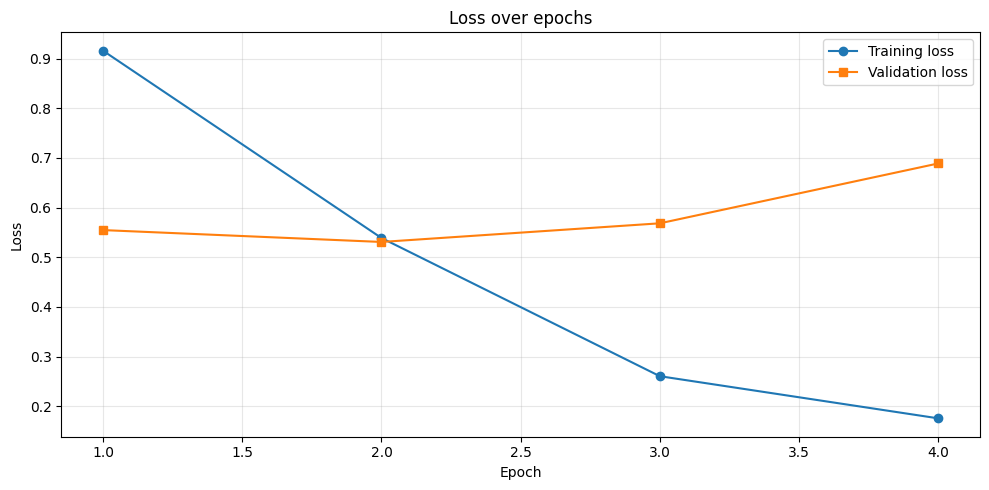

In [ ]:
"""Plot training and validation loss across completed epochs.

The loss histories are read from the notebook's global namespace. Each series is
plotted only when it contains data, so the cell can also display results when
only training or validation losses are available.
"""

# Retrieve recorded loss histories, defaulting to empty lists if not defined.
train_losses = list(globals().get("train_losses", []))
val_losses = list(globals().get("val_losses", []))


num_epochs = max(len(train_losses), len(val_losses))
train_x = list(range(1, len(train_losses) + 1))
val_x = list(range(1, len(val_losses) + 1))

plt.figure(figsize=(10, 5))
if train_losses:
    plt.plot(train_x, train_losses, label='Training loss', color='tab:blue', marker='o')
if val_losses:
    plt.plot(val_x, val_losses, label='Validation loss', color='tab:orange', marker='s')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss over epochs')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

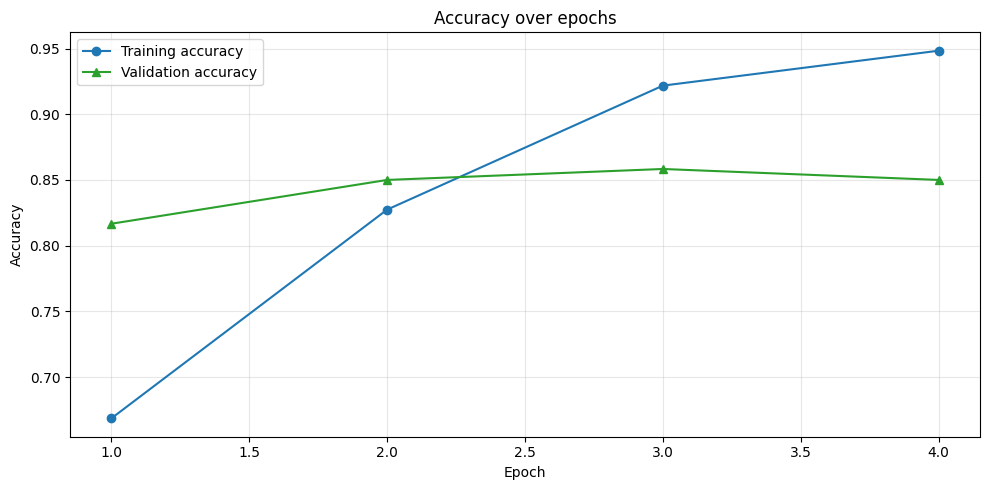

In [28]:
# These variables currently hold only the final epoch's scalar accuracy.

train_values = [float(value) for value in train_accuracys]
val_values = [float(value) for value in val_accuracys]

plt.figure(figsize=(10, 5))
if train_values:
    plt.plot(
        range(1, len(train_values) + 1),
        train_values,
        label="Training accuracy",
        color="tab:blue",
        marker="o",
    )
if val_values:
    plt.plot(
        range(1, len(val_values) + 1),
        val_values,
        label="Validation accuracy",
        color="tab:green",
        marker="^",
    )

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy over epochs")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
